# Especialización funcional entre cabezas de un bloque — vectores de daño por clase (2026-08-30)

Bloque B del capítulo (*circuit study*), extensión de `notebooks/22082026_ablation/ablation.ipynb`.
La ablación de ese notebook mide *cuánto* cae la accuracy global al apagar cada cabeza. Acá se mira
*a qué clases* le pega cada cabeza: se ablaciona una cabeza a la vez, se calcula la caída de accuracy
**por clase** (vector de dim 10), y se comparan esos "vectores de daño" entre cabezas del mismo bloque.

- Si dos cabezas tienen vectores de daño muy **parecidos** (coseno / Pearson altos) -> hacen un trabajo
  redundante: apagar una o la otra rompe las mismas clases.
- Si son **distintos / ortogonales** -> están especializadas en clases diferentes.

La hipótesis del capítulo es que el modelo penalizado ("interpretable") tiene cabezas con vectores de
daño **menos correlacionados** que el baseline (menos información compartida entre cabezas).

**Notebook parametrizable.** Se eligen `MODEL_NAME` y `BLOCK_IDX` en la única celda de configuración
de abajo; el resto corre igual. Cada corrida guarda su CSV + 3 heatmaps en `OUTPUT_DIR`, con
`MODEL_NAME` y `BLOCK_IDX` en el nombre, sin pisarse.

Sample de referencia: el **mismo n=1000** (primeras 1000 imágenes del test de CIFAR-10, con sus labels)
que `ablation.ipynb`, para que los números sean comparables entre notebooks y entre corridas.

## 0. Configuración — única celda que cambia entre corridas

In [1]:
# ======================================================================
#  CONFIGURACIÓN  —  lo único que se cambia entre corridas.
# ======================================================================
interpretable = False                       # o True
MODEL_NAME = f"vit-with-15-epochs{'-interpretable' if interpretable else ''}"
BLOCK_IDX  = 4                              # bloque a analizar, 1-indexed (block 1 = primer bloque),
                                           # igual que como se nombran los bloques en ablation.ipynb
                                           # ("skip block 1..4", "block 4"). Internamente se pasa a
                                           # 0-indexed para las funciones de ablación.
N_REF      = 1000                           # sample de referencia (mismo que ablation.ipynb)
# ======================================================================

import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision

# Misma convención que el resto de notebooks/: vive 2 niveles bajo la raíz del proyecto.
project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.model import ViTForClassfication
from modules.datasets import CIFAR10Dataset

torch.manual_seed(0)

# --- Resolver la carpeta del checkpoint (acepta nombre corto o completo) ---
experiments_root = project_root / "experimentation" / "experiments"
_candidates = [experiments_root / MODEL_NAME, experiments_root / f"{MODEL_NAME}-CIFAR10"]
exp_dir = next((c for c in _candidates if c.exists()), None)
if exp_dir is None:
    raise FileNotFoundError("No encontré la carpeta del experimento. Probé: "
                            + ", ".join(str(c) for c in _candidates))

# Etiquetas para los nombres de archivo de salida — distinguen corridas
# (MODEL_NAME contiene "interpretable" cuando corresponde; se añade el bloque).
MODEL_TAG = re.sub(r"[^0-9A-Za-z._-]+", "-", MODEL_NAME)
IS_INTERPRETABLE = "interpretable" in MODEL_NAME.lower()
RUN_TAG = f"{MODEL_TAG}_block{BLOCK_IDX}"

# Carpeta de salida dentro de la carpeta de experimentos existente del proyecto.
OUTPUT_DIR = experiments_root / "30082026_head_specialization"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, stem):
    """Guarda la figura como PNG en OUTPUT_DIR con MODEL_TAG y BLOCK_IDX en el nombre."""
    path = OUTPUT_DIR / f"{stem}_{RUN_TAG}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"guardado: {path.relative_to(project_root)}")
    return path


print(f"MODEL_NAME : {MODEL_NAME}  ({'interpretable' if IS_INTERPRETABLE else 'baseline / estándar'})")
print(f"BLOCK_IDX  : {BLOCK_IDX}  (1-indexed)")
print(f"exp_dir    : {exp_dir.relative_to(project_root)}")
print(f"OUTPUT_DIR : {OUTPUT_DIR.relative_to(project_root)}")
print(f"RUN_TAG    : {RUN_TAG}")
print(f"N_REF      : {N_REF}")

MODEL_NAME : vit-with-15-epochs  (baseline / estándar)
BLOCK_IDX  : 4  (1-indexed)
exp_dir    : experimentation/experiments/vit-with-15-epochs-CIFAR10
OUTPUT_DIR : experimentation/experiments/30082026_head_specialization
RUN_TAG    : vit-with-15-epochs_block4
N_REF      : 1000


## 1. Cargar el modelo

Mismo patrón que `ablation.ipynb`. El `assert` sobre `use_faster_attention` protege la ablación por
cabeza (asume `block.attention.heads` como submódulos separados). Se convierte `BLOCK_IDX` (1-indexed)
al índice 0-indexed `block_idx0` que usan las funciones de ablación.

In [2]:
with open(exp_dir / "config.json") as f:
    config = json.load(f)
with open(exp_dir / "metrics.json") as f:
    metrics = json.load(f)

assert not config["use_faster_attention"], (
    "Este notebook asume block.attention.heads (cabezas separadas); "
    "con use_faster_attention=True habría que adaptar la ablación por cabeza."
)

model = ViTForClassfication(config)
state_dict = torch.load(exp_dir / "model_final.pt", map_location="cpu")
model.load_state_dict(state_dict)
model.eval()

n_blocks    = len(model.encoder.blocks)
n_heads     = config["num_attention_heads"]
num_classes = config["num_classes"]

assert 1 <= BLOCK_IDX <= n_blocks, f"BLOCK_IDX debe estar en 1..{n_blocks} (1-indexed); recibí {BLOCK_IDX}"
block_idx0 = BLOCK_IDX - 1
assert len(model.encoder.blocks[block_idx0].attention.heads) == n_heads

head_labels = [f"head {h + 1}" for h in range(n_heads)]
print(f"Checkpoint {MODEL_NAME}: accuracy de entrenamiento = {metrics['accuracy']:.4f}")
print(f"bloques={n_blocks} | cabezas/bloque={n_heads} | clases={num_classes}")
print(f"Bloque a analizar: block {BLOCK_IDX}  (índice interno {block_idx0})  ->  {n_heads} cabezas")

Checkpoint vit-with-15-epochs: accuracy de entrenamiento = 0.5396
bloques=4 | cabezas/bloque=4 | clases=10
Bloque a analizar: block 4  (índice interno 3)  ->  4 cabezas


## 2. Sample de referencia (n = 1000, con labels)

Primeras `N_REF` imágenes del test de CIFAR-10 y sus labels de clase, apuntando a `experimentation/data`.
Idéntico a `ablation.ipynb`, así que la accuracy por clase de acá se puede cruzar con la de ese notebook.

In [3]:
dataset = CIFAR10Dataset()
dataset.testset = torchvision.datasets.CIFAR10(
    root=str(project_root / "experimentation" / "data"),
    train=False,
    download=True,
    transform=dataset.test_transform,
)
classes = list(dataset.classes)   # ('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

ref_images, ref_labels = dataset.get_samples_from_indices(range(N_REF), device="cpu", set="test")
_counts = torch.bincount(ref_labels, minlength=num_classes).tolist()
print(f"Sample de referencia: {tuple(ref_images.shape)}  (índices 0..{N_REF - 1} del test) — mismo que ablation.ipynb")
print("imágenes por clase:", {c: n for c, n in zip(classes, _counts)})
assert all(n > 0 for n in _counts), "Alguna clase no aparece en el sample; subir N_REF o cambiar los índices."

Sample de referencia: (1000, 3, 32, 32)  (índices 0..999 del test) — mismo que ablation.ipynb
imágenes por clase: {'plane': 103, 'car': 89, 'bird': 100, 'cat': 103, 'deer': 90, 'dog': 86, 'frog': 112, 'horse': 102, 'ship': 106, 'truck': 109}


## 3. Funciones: ablación por cabeza + accuracy por clase

`forward_with_head_ablated` es **la misma función de `notebooks/22082026_ablation/ablation.ipynb`**
(copiada tal cual): reconstruye la atención del bloque `ablate_layer_idx` a mano, corre cada cabeza por
separado y pone en **cero** la salida de `ablate_head_idx` antes de concatenar y proyectar; el resto del
modelo queda intacto. Con `ablate_layer_idx=None` no toca nada (se usa para el sanity check).

`per_class_accuracy` desglosa la accuracy en los 10 valores por clase.

In [4]:
@torch.no_grad()
def forward_with_head_ablated(model, x, ablate_layer_idx=None, ablate_head_idx=None):
    h = model.embedding(x)
    for i, block in enumerate(model.encoder.blocks):
        if i == ablate_layer_idx:
            attn_in = block.layernorm_1(h)
            head_outputs = []
            for hidx, head in enumerate(block.attention.heads):
                out, _ = head(attn_in)
                if hidx == ablate_head_idx:
                    out = torch.zeros_like(out)   # <- ablación: salida de esa cabeza a cero
                head_outputs.append(out)
            concat = torch.cat(head_outputs, dim=-1)
            attn_out = block.attention.output_projection(concat)
            attn_out = block.attention.output_dropout(attn_out)
            h = h + attn_out
            mlp_out = block.mlp(block.layernorm_2(h))
            h = h + mlp_out
        else:
            h, _ = block(h, output_attentions=False)
    return model.classifier(h[:, 0, :])


@torch.no_grad()
def accuracy_of(logits, labels):
    return (logits.argmax(dim=-1) == labels).float().mean().item()


@torch.no_grad()
def per_class_accuracy(logits, labels, num_classes):
    """Vector de dim num_classes: accuracy dentro de cada clase (correctos_c / total_c)."""
    preds = logits.argmax(dim=-1)
    accs = np.full(num_classes, np.nan)
    for c in range(num_classes):
        mask = labels == c
        n_c = int(mask.sum())
        if n_c > 0:
            accs[c] = (preds[mask] == labels[mask]).float().mean().item()
    return accs


# Sanity check: sin ablación, la reimplementación manual debe coincidir EXACTO con el forward normal.
with torch.no_grad():
    direct_logits, _ = model(ref_images, output_attentions=False)
head_fn_logits = forward_with_head_ablated(model, ref_images, ablate_layer_idx=None, ablate_head_idx=None)
_diff = (direct_logits - head_fn_logits).abs().max().item()
print(f"Diferencia máxima (forward_with_head_ablated, sin ablar) vs forward normal: {_diff:.2e}")
assert _diff < 1e-5, "Sin ablación la función debe reproducir el forward normal"
print("OK - la reimplementación manual es fiel al forward original.")

Diferencia máxima (forward_with_head_ablated, sin ablar) vs forward normal: 0.00e+00
OK - la reimplementación manual es fiel al forward original.


## Tarea 1 — Accuracy baseline por clase (sin ablación)

Forward pass completo sobre el sample de referencia, sin tocar nada. Se guarda el vector
`accuracy_baseline_per_class` (dim 10) que es la referencia contra la que se mide el daño de cada cabeza.

In [5]:
baseline_logits = direct_logits   # ya calculado en el sanity check (forward normal)
accuracy_baseline_global = accuracy_of(baseline_logits, ref_labels)
accuracy_baseline_per_class = per_class_accuracy(baseline_logits, ref_labels, num_classes)

print(f"Accuracy global baseline (n={N_REF}): {accuracy_baseline_global:.4f}\n")
print("Accuracy baseline por clase:")
for c, name in enumerate(classes):
    print(f"  {name:>6}: {accuracy_baseline_per_class[c]:.4f}")

Accuracy global baseline (n=1000): 0.5470

Accuracy baseline por clase:
   plane: 0.6117
     car: 0.6292
    bird: 0.6400
     cat: 0.1262
    deer: 0.2222
     dog: 0.3837
    frog: 0.8661
   horse: 0.8235
    ship: 0.4340
   truck: 0.6514


## Tarea 2 — Vector de daño por clase, por cada cabeza del bloque

Para cada una de las `n_heads` cabezas de `block BLOCK_IDX`: se ablaciona **solo esa cabeza**, se corre
el forward sobre el mismo sample, se calcula la accuracy por clase, y

```
damage_vector[head] = accuracy_baseline_per_class - accuracy_ablated_per_class   # dim 10
```

Daño positivo = esa clase empeora al apagar la cabeza (la cabeza ayudaba a esa clase). Daño negativo =
la clase mejora al apagarla. Los `n_heads` vectores se apilan en `damage_matrix` de shape `(n_heads, 10)`.

In [6]:
damage_matrix = np.zeros((n_heads, num_classes))
ablated_acc_per_class = np.zeros((n_heads, num_classes))
for hidx in range(n_heads):
    logits = forward_with_head_ablated(model, ref_images, ablate_layer_idx=block_idx0, ablate_head_idx=hidx)
    acc_c = per_class_accuracy(logits, ref_labels, num_classes)
    ablated_acc_per_class[hidx] = acc_c
    damage_matrix[hidx] = accuracy_baseline_per_class - acc_c
    drop_global = accuracy_baseline_global - accuracy_of(logits, ref_labels)
    print(f"block {BLOCK_IDX}, head {hidx + 1}: caída global = {drop_global:+.4f}  |  "
          f"daño por clase [min {damage_matrix[hidx].min():+.3f}, max {damage_matrix[hidx].max():+.3f}]")

print("\ndamage_matrix (filas = cabezas, columnas = clases):")
print(pd.DataFrame(damage_matrix, index=head_labels, columns=classes).round(3))

block 4, head 1: caída global = +0.0170  |  daño por clase [min -0.039, max +0.105]
block 4, head 2: caída global = +0.0120  |  daño por clase [min -0.029, max +0.067]
block 4, head 3: caída global = +0.0090  |  daño por clase [min -0.057, max +0.090]
block 4, head 4: caída global = +0.0070  |  daño por clase [min -0.049, max +0.134]

damage_matrix (filas = cabezas, columnas = clases):
        plane    car  bird    cat   deer    dog   frog  horse   ship  truck
head 1  0.000 -0.011  0.02 -0.039  0.056  0.105  0.027  0.020 -0.009  0.018
head 2  0.000  0.067  0.03 -0.029  0.011  0.035 -0.018  0.020 -0.028  0.046
head 3  0.019 -0.022  0.09 -0.010 -0.044  0.070 -0.009  0.010 -0.057  0.046
head 4 -0.029 -0.022  0.04 -0.049  0.078 -0.035  0.134 -0.039 -0.009 -0.009


guardado: experimentation/experiments/30082026_head_specialization/damage_by_class_heatmap_vit-with-15-epochs_block4.png


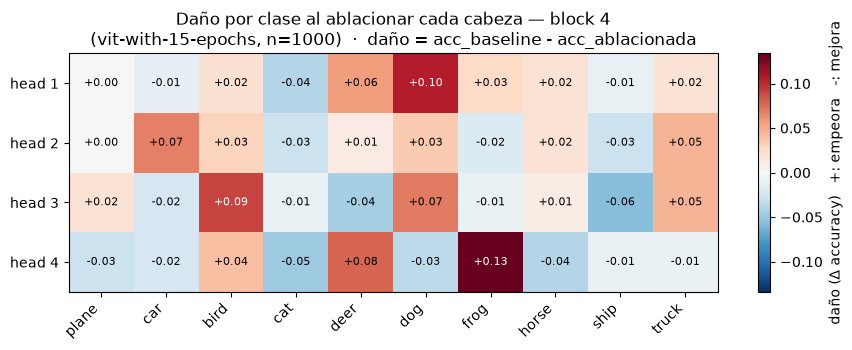

In [7]:
# --- Heatmap de la matriz de daño por clase (cabezas x clases) --------
# Escala divergente centrada en 0 (rojo = daña esa clase, azul = la mejora),
# simétrica, para poder comparar entre corridas.
vmax_dmg = float(np.nanmax(np.abs(damage_matrix)))
vmax_dmg = vmax_dmg if vmax_dmg > 0 else 1e-6

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(damage_matrix, cmap="RdBu_r", vmin=-vmax_dmg, vmax=vmax_dmg, aspect="auto")
ax.set_xticks(range(num_classes)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
for hh in range(n_heads):
    for cc in range(num_classes):
        v = damage_matrix[hh, cc]
        ax.text(cc, hh, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * vmax_dmg else "black")
ax.set_title(f"Daño por clase al ablacionar cada cabeza — block {BLOCK_IDX}\n"
             f"({MODEL_NAME}, n={N_REF})  ·  daño = acc_baseline - acc_ablacionada")
fig.colorbar(im, ax=ax, label="daño (Δ accuracy)   +: empeora   -: mejora")
plt.tight_layout()
save_fig(fig, "damage_by_class_heatmap")
plt.show()

## Tarea 3 — Similitud pareada entre vectores de daño

Con `damage_matrix` (4×10), para los 6 pares `(1,2) (1,3) (1,4) (2,3) (2,4) (3,4)`:

- **Coseno**: `<d_i, d_j> / (||d_i|| ||d_j||)`. Sensible tanto a la *dirección* (qué clases) como al
  hecho de que ambos vectores apunten "hacia daño positivo".
- **Pearson** (control): coseno **después de centrar** cada vector (restarle su media). Al quitar la
  media, controla por el caso "esta cabeza daña más en general a todas las clases por igual" y deja
  solo el patrón *relativo* entre clases — si Pearson es bajo pero coseno alto, el parecido venía sobre
  todo de la magnitud media, no de atacar las mismas clases.

Se arman dos matrices `4×4` simétricas (diagonal = 1) y se reporta el **promedio de las 6 similitudes
fuera de la diagonal** para cada métrica: un escalar de coseno y un escalar de Pearson por corrida.

In [8]:
from modules.similarity import offdiag_mean, pairwise_similarity_matrix


cosine_matrix  = pairwise_similarity_matrix(damage_matrix, "cosine")
pearson_matrix = pairwise_similarity_matrix(damage_matrix, "pearson")

promedio_similitud_coseno  = offdiag_mean(cosine_matrix)
promedio_similitud_pearson = offdiag_mean(pearson_matrix)

print("Matriz de similitud COSENO (vectores de daño):")
print(pd.DataFrame(cosine_matrix, index=head_labels, columns=head_labels).round(3))
print("\nMatriz de similitud PEARSON (vectores de daño):")
print(pd.DataFrame(pearson_matrix, index=head_labels, columns=head_labels).round(3))
print(f"\npromedio_similitud_coseno  (6 pares) = {promedio_similitud_coseno:.4f}")
print(f"promedio_similitud_pearson (6 pares) = {promedio_similitud_pearson:.4f}")

Matriz de similitud COSENO (vectores de daño):
        head 1  head 2  head 3  head 4
head 1   1.000   0.445   0.443   0.267
head 2   0.445   1.000   0.481  -0.135
head 3   0.443   0.481   1.000  -0.127
head 4   0.267  -0.135  -0.127   1.000

Matriz de similitud PEARSON (vectores de daño):
        head 1  head 2  head 3  head 4
head 1   1.000   0.327   0.403   0.247
head 2   0.327   1.000   0.447  -0.193
head 3   0.403   0.447   1.000  -0.152
head 4   0.247  -0.193  -0.152   1.000

promedio_similitud_coseno  (6 pares) = 0.2288
promedio_similitud_pearson (6 pares) = 0.1797


guardado: experimentation/experiments/30082026_head_specialization/cosine_similarity_heatmap_vit-with-15-epochs_block4.png


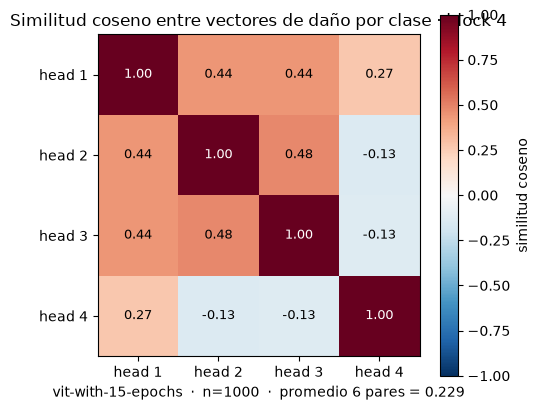

guardado: experimentation/experiments/30082026_head_specialization/pearson_similarity_heatmap_vit-with-15-epochs_block4.png


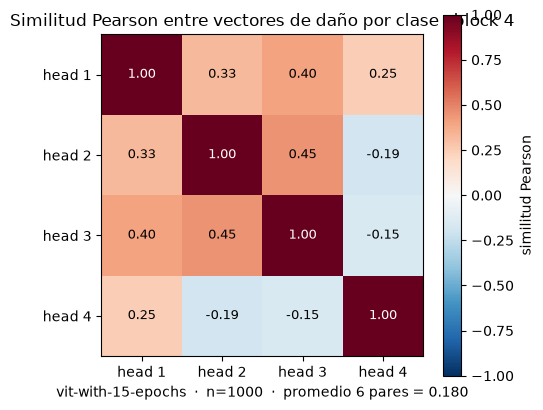

In [9]:
# --- Heatmaps de las dos matrices de similitud (4x4) -----------------
# Escala fija [-1, 1] para comparar entre corridas.
for M, name, stem in [
    (cosine_matrix,  "coseno",  "cosine_similarity_heatmap"),
    (pearson_matrix, "Pearson", "pearson_similarity_heatmap"),
]:
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1.0, vmax=1.0)
    ax.set_xticks(range(n_heads)); ax.set_xticklabels(head_labels)
    ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
    for i in range(n_heads):
        for j in range(n_heads):
            v = M[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="center",
                    fontsize=9, color="white" if abs(np.nan_to_num(v)) > 0.6 else "black")
    mean_val = promedio_similitud_coseno if name == "coseno" else promedio_similitud_pearson
    ax.set_title(f"Similitud {name} entre vectores de daño por clase · block {BLOCK_IDX}")
    ax.set_xlabel(f"{MODEL_NAME}  ·  n={N_REF}  ·  promedio 6 pares = {mean_val:.3f}")
    fig.colorbar(im, ax=ax, label=f"similitud {name}")
    plt.tight_layout()
    save_fig(fig, stem)
    plt.show()

## Tabla resumen (CSV)

Un único CSV con todo lo del experimento: `accuracy_baseline_per_class` (10), `damage_vector` por
cabeza (4×10), matriz coseno (4×4), matriz Pearson (4×4) y los dos escalares resumen. Cada fila lleva
su etiqueta; las columnas de clase se usan para los vectores por clase, las de cabeza para las matrices
4×4, y la columna `scalar` para los dos promedios.

In [10]:
rows = {}
rows["accuracy_baseline_per_class"] = {name: accuracy_baseline_per_class[c] for c, name in enumerate(classes)}
for h in range(n_heads):
    rows[f"damage_vector__{head_labels[h]}"] = {name: damage_matrix[h, c] for c, name in enumerate(classes)}
for h in range(n_heads):
    rows[f"cosine_similarity__{head_labels[h]}"] = {head_labels[j]: cosine_matrix[h, j] for j in range(n_heads)}
for h in range(n_heads):
    rows[f"pearson_similarity__{head_labels[h]}"] = {head_labels[j]: pearson_matrix[h, j] for j in range(n_heads)}
rows["promedio_similitud_coseno"]  = {"scalar": promedio_similitud_coseno}
rows["promedio_similitud_pearson"] = {"scalar": promedio_similitud_pearson}

summary_df = pd.DataFrame.from_dict(rows, orient="index")
summary_df = summary_df.reindex(columns=classes + head_labels + ["scalar"])
summary_df.index.name = "row"
summary_df.insert(0, "model_name", MODEL_NAME)
summary_df.insert(1, "block_idx", BLOCK_IDX)

csv_path = OUTPUT_DIR / f"head_specialization_{RUN_TAG}.csv"
summary_df.to_csv(csv_path)
print(f"guardado: {csv_path.relative_to(project_root)}")
summary_df

guardado: experimentation/experiments/30082026_head_specialization/head_specialization_vit-with-15-epochs_block4.csv


,model_name,block_idx,plane,car,bird,cat,deer,dog,frog,horse,ship,truck,head 1,head 2,head 3,head 4,scalar
row,,,,,,,,,,,,,,,,,
accuracy_baseline_per_class,vit-with-15-epochs,4,0.611650,0.629214,0.64,0.126214,0.222222,0.383721,0.866071,0.823529,0.433962,0.651376,NaN,NaN,NaN,NaN,NaN
damage_vector__head 1,vit-with-15-epochs,4,0.000000,-0.011236,0.02,-0.038835,0.055556,0.104651,0.026786,0.019608,-0.009434,0.018349,NaN,NaN,NaN,NaN,NaN
damage_vector__head 2,vit-with-15-epochs,4,0.000000,0.067416,0.03,-0.029126,0.011111,0.034884,-0.017857,0.019608,-0.028302,0.045872,NaN,NaN,NaN,NaN,NaN
damage_vector__head 3,vit-with-15-epochs,4,0.019417,-0.022472,0.09,-0.009709,-0.044444,0.069767,-0.008929,0.009804,-0.056604,0.045872,NaN,NaN,NaN,NaN,NaN
damage_vector__head 4,vit-with-15-epochs,4,-0.029126,-0.022472,0.04,-0.048544,0.077778,-0.034884,0.133929,-0.039216,-0.009434,-0.009174,NaN,NaN,NaN,NaN,NaN
cosine_similarity__head 1,vit-with-15-epochs,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.444773,0.442603,0.266519,NaN
cosine_similarity__head 2,vit-with-15-epochs,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.444773,1.000000,0.481286,-0.134928,NaN
cosine_similarity__head 3,vit-with-15-epochs,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.442603,0.481286,1.000000,-0.127443,NaN
cosine_similarity__head 4,vit-with-15-epochs,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.266519,-0.134928,-0.127443,1.000000,NaN


## Resultado principal

In [11]:
line = "=" * 68
print(line)
print(f"  RESULTADO PRINCIPAL  —  {MODEL_NAME}  ·  block {BLOCK_IDX}  ·  n={N_REF}")
print(line)
print(f"  promedio_similitud_coseno   (6 pares de cabezas) = {promedio_similitud_coseno:+.4f}")
print(f"  promedio_similitud_pearson  (6 pares de cabezas) = {promedio_similitud_pearson:+.4f}")
print(line)
print("  Más bajo = cabezas MÁS especializadas (vectores de daño por clase menos")
print("  parecidos entre sí). Comparar este par de números entre la corrida baseline")
print("  y la interpretable, y entre bloques.")
print(line)

  RESULTADO PRINCIPAL  —  vit-with-15-epochs  ·  block 4  ·  n=1000
  promedio_similitud_coseno   (6 pares de cabezas) = +0.2288
  promedio_similitud_pearson  (6 pares de cabezas) = +0.1797
  Más bajo = cabezas MÁS especializadas (vectores de daño por clase menos
  parecidos entre sí). Comparar este par de números entre la corrida baseline
  y la interpretable, y entre bloques.


## Para reflexionar / siguientes pasos

- Correr con `MODEL_NAME = "vit-with-15-epochs"` y con `"vit-with-15-epochs-interpretable"`, para el
  mismo `BLOCK_IDX`, y comparar `promedio_similitud_coseno` / `promedio_similitud_pearson`. La hipótesis
  del capítulo (B) es que el modelo penalizado los tiene **más bajos** (cabezas menos redundantes).
- Repetir barriendo `BLOCK_IDX` sobre los 4 bloques: ¿la especialización aparece sobre todo en los
  bloques finales (los que ya "deciden" la clase, cf. logit lens) o está repartida?
- El heatmap de daño por clase permite leer *qué* clases concentra cada cabeza: si en el modelo
  interpretable cada cabeza tiene su propio conjunto de clases "rojas" y en el baseline varias cabezas
  comparten las mismas, eso es evidencia cualitativa directa de especialización.
- Complemento natural (mismo sample): repetir con 2-3 semillas (**C.6**, *universality*) sobre estos
  dos escalares resumen.